# Banking Portfolio & Client Analytics — Exploratory Data Analysis (EDA)

**Author:** Banking Analytics Portfolio Project  
**Target Scope:** Customer Segmentation, Balance Aggregations, High-Value Deposit Review & Portfolio Performance.  
**Dataset:** 3,000 banking records (2,940 distinct clients) across 25 demographic, balance, and relationship attributes.

---

### Business Objectives
1. **Client Segmentation:** Profile client distribution across income bands, occupations, nationalities, and loyalty tiers.
2. **Portfolio Liquidity & Deposit Analysis:** Analyze checking, savings, and deposit relationships to uncover customer liquidity patterns.
3. **Credit & Lending Exposure:** Evaluate bank loans, business lending, and credit card balances across risk weights and income segments.
4. **High-Value Deposit & Advisor Review:** Identify top-decile deposit clients for advisor review and note the absence of an unassigned-advisor segment.

> **Governance Note:** This is descriptive portfolio analytics. The dataset contains no historical credit defaults or repayment outcomes; findings guide portfolio strategy rather than credit underwriting.

In [1]:
# Standard Data Science & Visualization Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Visual presentation settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', None)

## 1. Data Ingestion & Schema Profiling

Load the primary fact table (`Banking.csv`) using dynamic path resolution and UTF-8 BOM encoding protection.

> **Data grain:** the file contains 3,000 banking records but only 2,940 distinct client IDs. Treat each row as a banking record; use distinct client counts for client-level KPIs.

In [2]:
# Dynamic path resolution for notebook execution from root or notebooks/ directory
data_path = Path('../Banking.csv')
if not data_path.exists():
    data_path = Path('Banking.csv')

# Load with utf-8-sig to handle optional byte-order-mark cleanly
df = pd.read_csv(data_path, encoding='utf-8-sig')

print(f"Dataset Dimensions: {df.shape[0]:,} rows | {df.shape[1]} columns")
df.head()

Dataset Dimensions: 3,000 rows | 25 columns


,Client ID,Name,Age,Location ID,Joined Bank,Banking Contact,Nationality,Occupation,Fee Structure,Loyalty Classification,Estimated Income,Superannuation Savings,Amount of Credit Cards,Credit Card Balance,Bank Loans,Bank Deposits,Checking Accounts,Saving Accounts,Foreign Currency Account,Business Lending,Properties Owned,Risk Weighting,BRId,GenderId,IAId
0,IND81288,Raymond Mills,24,34324,06-05-2019,Anthony Torres,American,Safety Technician IV,High,Jade,75384.77,17677.95,1,484.54,776242.92,1485828.64,603617.88,607332.46,12249.96,1134475.30,1,2,1,1,1
1,IND65833,Julia Spencer,23,42205,10-12-2001,Jonathan Hawkins,African,Software Consultant,High,Jade,289834.31,17398.92,1,2256.88,1270615.43,641482.79,229521.37,344635.16,61162.31,2000526.10,1,3,2,1,2
2,IND47499,Stephen Murray,27,7314,25-01-2010,Anthony Berry,European,Help Desk Operator,High,Gold,169935.23,42825.90,2,4568.74,1052715.84,1033401.59,652674.69,203054.35,79071.78,548137.58,1,3,3,2,3
3,IND72498,Virginia Garza,40,34594,28-03-2019,Steve Diaz,American,Geologist II,Mid,Silver,356808.11,5473.15,2,4205.00,121195.06,1048157.49,1048157.49,234685.02,57513.65,1148402.29,0,4,4,1,4
4,IND60181,Melissa Sanders,46,41269,20-07-2012,Shawn Long,American,Assistant Professor,Mid,Platinum,130711.68,48077.60,1,3779.49,1048301.95,487782.53,446644.25,128351.45,30012.14,1674412.12,0,3,1,2,5


In [3]:
# Inspect schema, column datatypes, and null completeness
print("=== Missing Values Audit ===")
nulls = df.isnull().sum()
print(f"Total columns with missing values: {(nulls > 0).sum()}")
if (nulls > 0).sum() == 0:
    print("✓ Zero missing values detected across all 25 features.")

print("\n=== Schema Overview ===")
df.info()

=== Missing Values Audit ===
Total columns with missing values: 0
✓ Zero missing values detected across all 25 features.

=== Schema Overview ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Client ID                 3000 non-null   object 
 1   Name                      3000 non-null   object 
 2   Age                       3000 non-null   int64  
 3   Location ID               3000 non-null   int64  
 4   Joined Bank               3000 non-null   object 
 5   Banking Contact           3000 non-null   object 
 6   Nationality               3000 non-null   object 
 7   Occupation                3000 non-null   object 
 8   Fee Structure             3000 non-null   object 
 9   Loyalty Classification    3000 non-null   object 
 10  Estimated Income          3000 non-null   float64
 11  Superannuation Savings    3

## 2. Feature Engineering & Type Standardization

Align calculated features with Power BI DAX models:
- **Date Conversion:** Parse `Joined Bank` (`%d-%m-%Y`).
- **Tenure / Engagement:** Calculate total days with the bank.
- **Income Band:** Segment `Estimated Income` into `Low` (<$100k), `Mid` ($100k-$300k), and `High` (>$300k).
- **Total Liquidity & Total Lending:** Compute aggregated balance metrics per client.

In [4]:
# 1. Parse date of joining
df['Joined Bank'] = pd.to_datetime(df['Joined Bank'], format='%d-%m-%Y')

# 2. Calculate engagement days and tenure in years
reference_date = pd.to_datetime('today')
df['Engagement Days'] = (reference_date - df['Joined Bank']).dt.days
df['Tenure Years'] = (df['Engagement Days'] / 365.25).round(1)

# 3. Income band segmentation aligned with Power BI definition
income_bins = [0, 100000, 300000, float('inf')]
income_labels = ['Low', 'Mid', 'High']
df['Income Band'] = pd.cut(df['Estimated Income'], bins=income_bins, labels=income_labels, include_lowest=True)

# 4. Consolidated financial totals per client
df['Total Deposits'] = df['Bank Deposits'] + df['Saving Accounts'] + df['Checking Accounts'] + df['Foreign Currency Account']
df['Total Loans'] = df['Bank Loans'] + df['Business Lending'] + df['Credit Card Balance']

print("Derived features created successfully:")
df[['Client ID', 'Joined Bank', 'Tenure Years', 'Income Band', 'Total Deposits', 'Total Loans']].head()

Derived features created successfully:


,Client ID,Joined Bank,Tenure Years,Income Band,Total Deposits,Total Loans
0,IND81288,2019-05-06,7.5,Low,2709028.94,1911202.76
1,IND65833,2001-12-10,24.9,Mid,1276801.63,3273398.41
2,IND47499,2010-01-25,16.8,Mid,1968202.41,1605422.16
3,IND72498,2019-03-28,7.6,High,2388513.65,1273802.35
4,IND60181,2012-07-20,14.3,Mid,1092790.37,2726493.56


## 3. Categorical Distributions (Client Demographics & Segmentation)

Explore customer distribution across income segments, nationality, risk rating, and loyalty tiers.

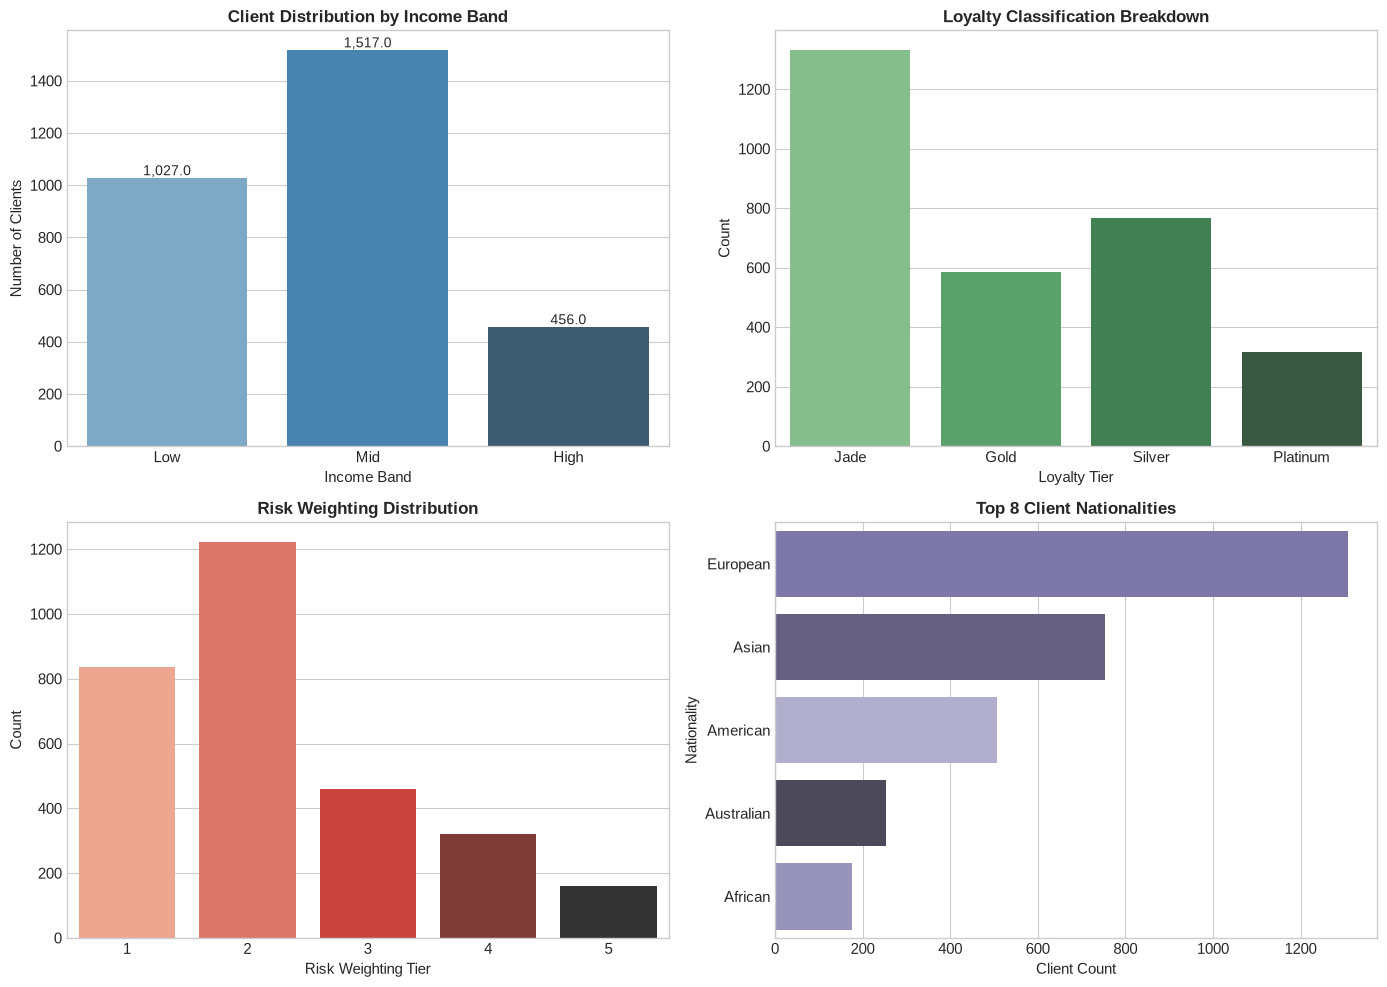

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Income Band Distribution
sns.countplot(data=df, x='Income Band', order=['Low', 'Mid', 'High'], hue='Income Band', palette='Blues_d', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Client Distribution by Income Band', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Income Band')
axes[0, 0].set_ylabel('Number of Clients')
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'{p.get_height():,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=10)

# 2. Loyalty Classification
sns.countplot(data=df, x='Loyalty Classification', hue='Loyalty Classification', palette='Greens_d', legend=False, ax=axes[0, 1])
axes[0, 1].set_title('Loyalty Classification Breakdown', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Loyalty Tier')
axes[0, 1].set_ylabel('Count')

# 3. Risk Weighting
sns.countplot(data=df, x='Risk Weighting', hue='Risk Weighting', palette='Reds_d', legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Risk Weighting Distribution', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Risk Weighting Tier')
axes[1, 0].set_ylabel('Count')

# 4. Top 8 Nationalities
top_nat = df['Nationality'].value_counts().nlargest(8).index
sns.countplot(data=df[df['Nationality'].isin(top_nat)], y='Nationality', order=top_nat, hue='Nationality', palette='Purples_d', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Top 8 Client Nationalities', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Client Count')

plt.tight_layout()
plt.show()


## 4. Financial Balance Distributions (Univariate Analysis)

Examine the skewness, spread, and central tendencies of customer balances across deposit and lending products.

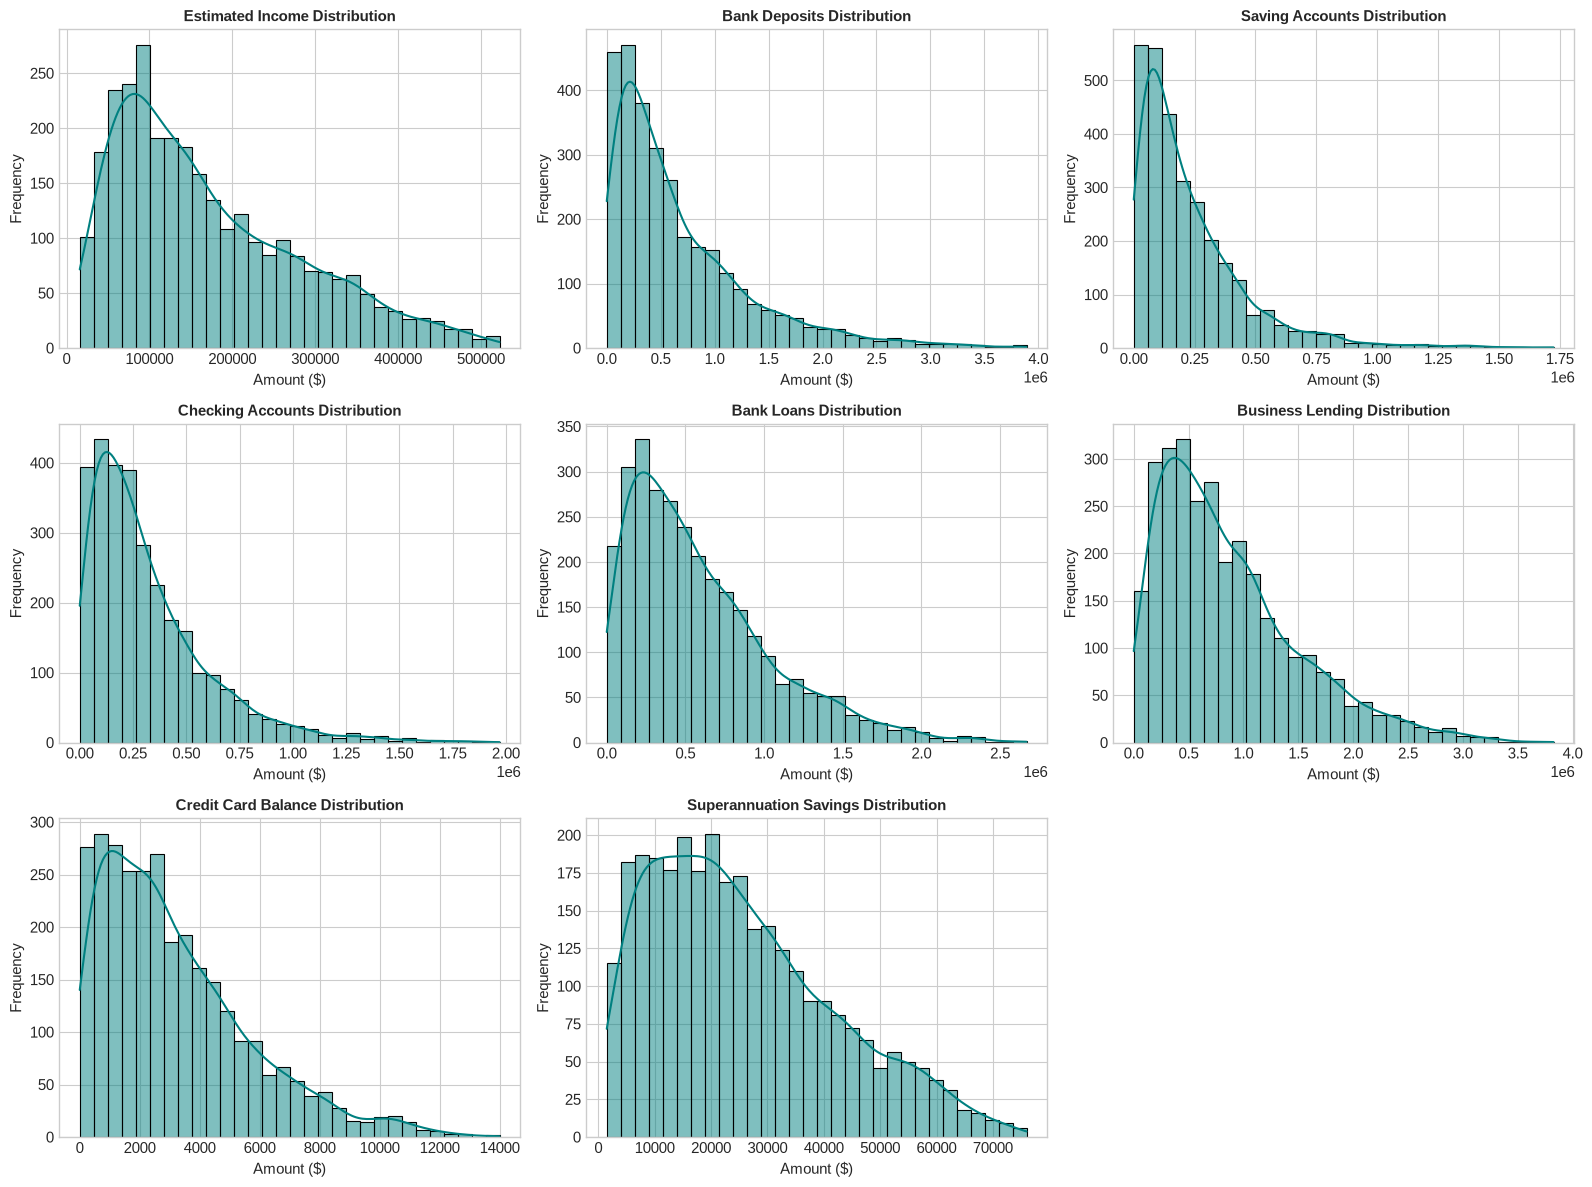

In [6]:
balance_cols = [
    'Estimated Income', 'Bank Deposits', 'Saving Accounts', 'Checking Accounts',
    'Bank Loans', 'Business Lending', 'Credit Card Balance', 'Superannuation Savings'
]

plt.figure(figsize=(16, 12))
for i, col in enumerate(balance_cols, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[col], kde=True, color='teal', bins=30)
    plt.title(f'{col} Distribution', fontsize=11, fontweight='bold')
    plt.xlabel('Amount ($)')
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [7]:
# Parametric summary of balance metrics
df[balance_cols].describe().round(2)

,Estimated Income,Bank Deposits,Saving Accounts,Checking Accounts,Bank Loans,Business Lending,Credit Card Balance,Superannuation Savings
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,171305.03,671560.19,232908.35,321092.95,591386.16,866759.81,3176.21,25531.60
std,111935.81,645716.86,230007.78,282079.55,457557.04,641230.32,2497.09,16259.95
min,15919.48,0.00,0.00,0.00,0.00,0.00,1.17,1482.03
25%,82906.60,204400.38,74794.40,119947.53,239628.14,374825.14,1236.63,12513.78
50%,142313.48,463316.46,164086.56,242815.66,479793.40,711314.66,2560.81,22357.36
75%,242290.30,942754.63,315575.00,434874.94,825813.04,1185110.08,4522.63,35464.74
max,522330.26,3890598.08,1724118.36,1969923.08,2667556.66,3825961.94,13991.99,75963.90


## 5. Correlation & Inter-Product Relationships

Evaluate multi-product holding and correlation patterns to inform cross-sell and liquidity management.

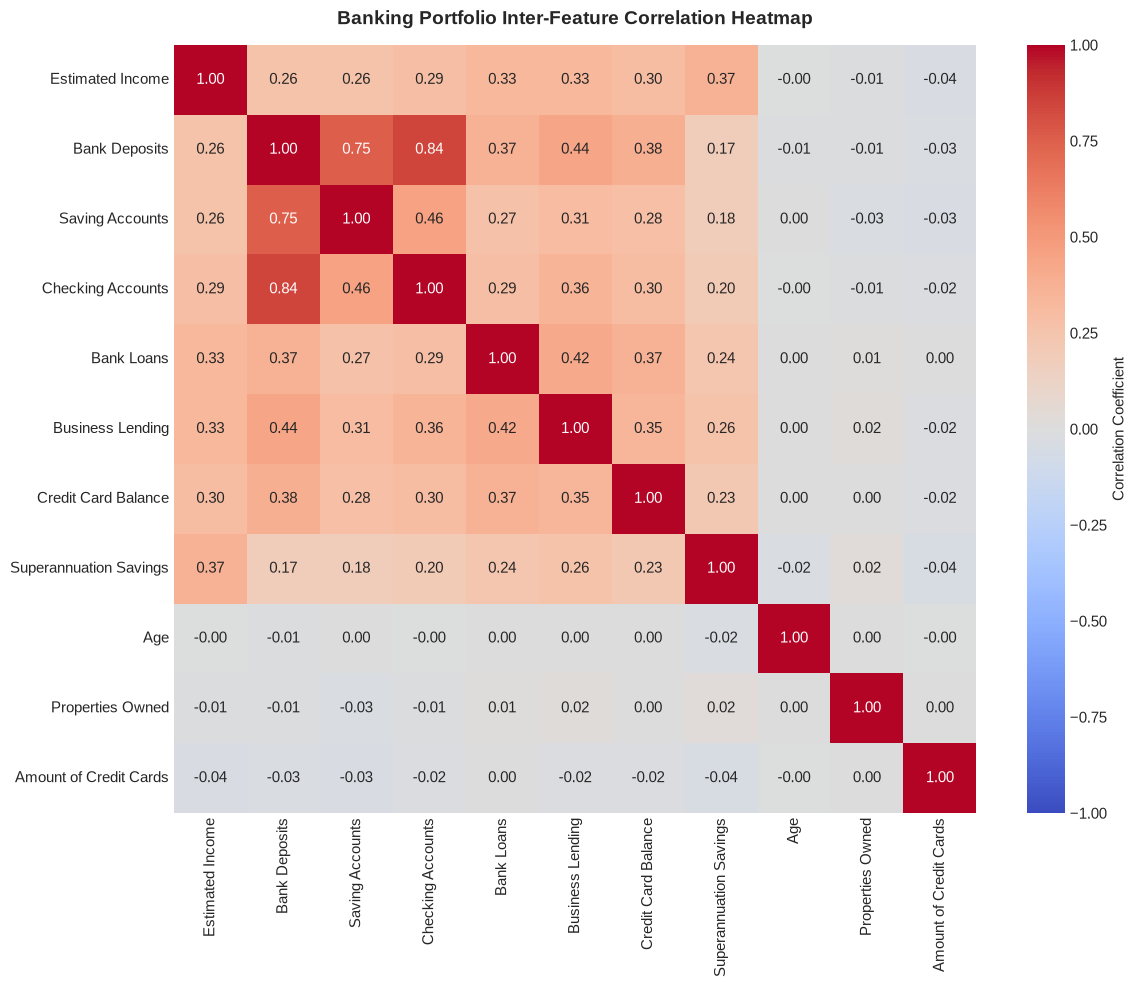

In [8]:
# Correlation matrix of financial features
corr_cols = balance_cols + ['Age', 'Properties Owned', 'Amount of Credit Cards']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Banking Portfolio Inter-Feature Correlation Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

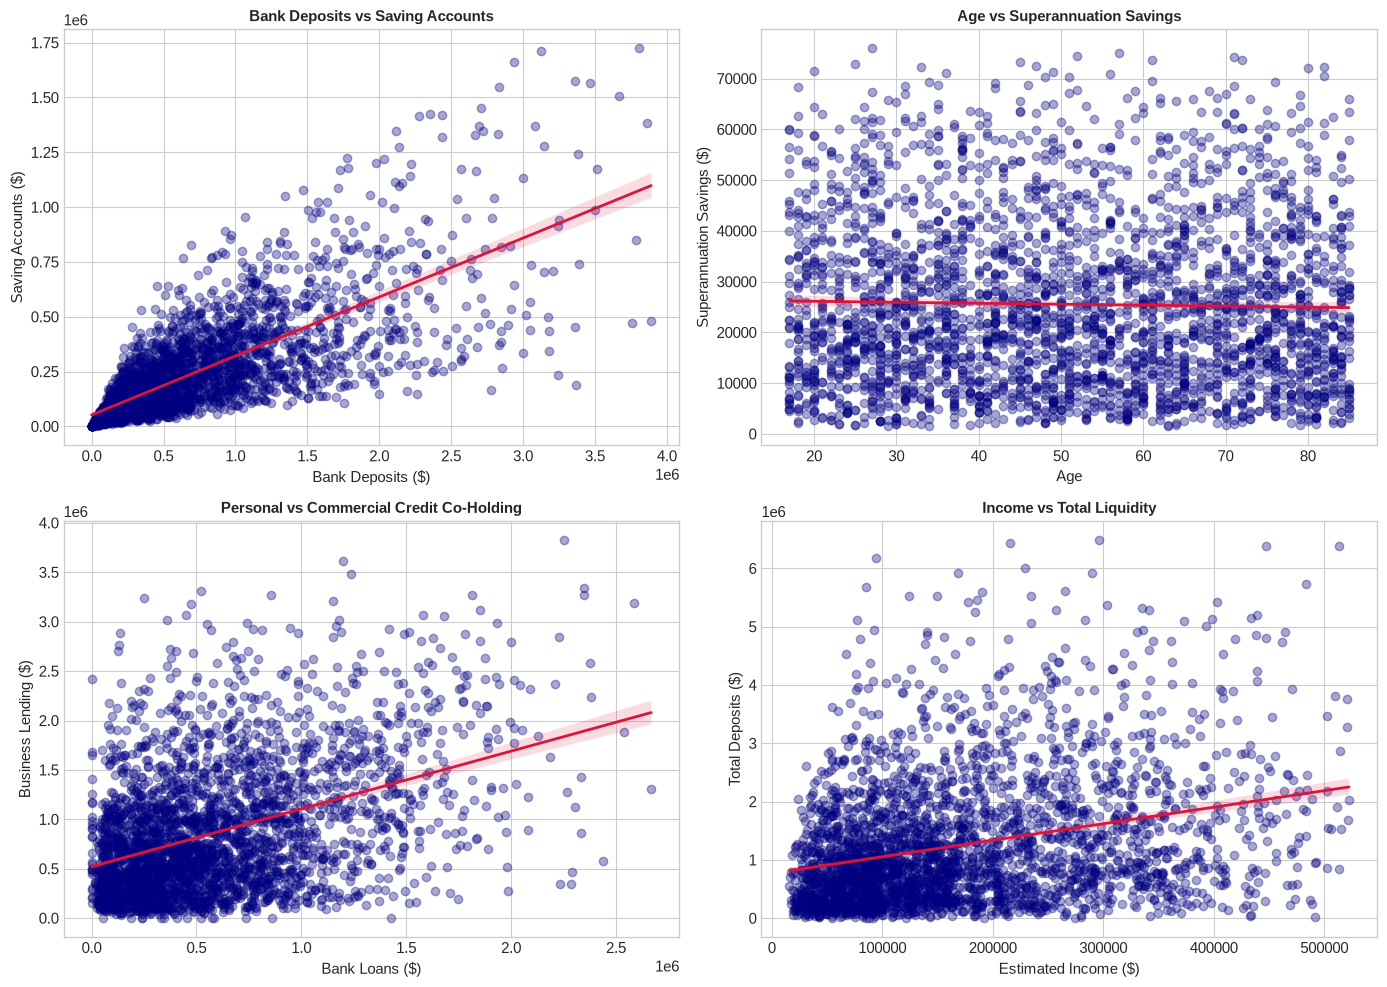

In [9]:
# Key Bivariate Relationships with Regression Fit
bivariate_pairs = [
    ('Bank Deposits', 'Saving Accounts', 'Bank Deposits vs Saving Accounts'),
    ('Age', 'Superannuation Savings', 'Age vs Superannuation Savings'),
    ('Bank Loans', 'Business Lending', 'Personal vs Commercial Credit Co-Holding'),
    ('Estimated Income', 'Total Deposits', 'Income vs Total Liquidity')
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (x, y, title) in zip(axes.flatten(), bivariate_pairs):
    sns.regplot(
        data=df, x=x, y=y, ax=ax,
        scatter_kws={'alpha': 0.35, 'color': 'navy'},
        line_kws={'color': 'crimson', 'linewidth': 2}
    )
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(f'{x} ($)' if 'Age' not in x else x)
    ax.set_ylabel(f'{y} ($)')

plt.tight_layout()
plt.show()


## 6. Business Insights & Strategic Portfolio Recommendations

### 1. Liquidity concentration is real
- `Bank Deposits` correlates strongly with `Checking Accounts` (**r = 0.84**) and `Saving Accounts` (**r = 0.76**).
- **Business action:** use automated sweep accounts and tiered deposit products to retain liquidity in higher-margin instruments.

### 2. The portfolio is loan-heavy
- Total deposits are **$3.77B** against **$4.38B** in loans, producing a **116.4% loan-to-deposit ratio**.
- **Business action:** monitor funding mix and deposit growth. Treat LDR as a descriptive portfolio ratio, not a credit-risk model.

### 3. Fee revenue is concentrated in the High fee tier
- The High fee structure generates **67.7%** of the **$158.2M** estimated fee base.
- By income band, **Mid-income clients generate 54.0%** of fees, Low-income 24.8%, and High-income 21.2%.
- **Business action:** review retention and pricing for high-fee-tier clients, and do not assume fee tier and income tier are the same population.

### 4. Age is not a proxy for wealth in this dataset
- `Age` vs `Superannuation Savings` has a correlation of **-0.02**, and `Age` vs `Estimated Income` is approximately **0.00**.
- **Business action:** segment on balances and income, not age. The "mature affluent" narrative is not supported by this synthetic sample.

### 5. High-value deposits should be defined by the top decile
- The top decile of total deposits starts at **$2.72M** and contains **300 records**.
- Only **5** of those records have no bank loan. There are **22 advisors** with 88–177 records each (87–177 distinct clients), and every record has an advisor ID.
- **Business action:** prioritise top-decile clients for advisor review and use advisor caseload/coverage. There is no "unassigned advisor" population in this dataset.

### 6. Cross-sell whitespace is limited
- 99.1% of records have a bank loan, 99.5% have business lending, 100% have a credit card balance, and 98.9% have deposits/savings/checking.
- Only **27** records have no bank loan and **14** have no business lending.
- **Business action:** focus on deepening product usage and balance growth rather than assuming large untapped product gaps.

### 7. Data-quality caveat
- 3,000 records map to 2,940 distinct client IDs; 59 client IDs appear more than once (60 extra records).
- Use `COUNT(DISTINCT client_id)` / `DISTINCTCOUNT` for client KPIs, and keep record-level analysis explicit about its grain.

---

*Descriptive analytics only: the dataset contains no default, repayment, approval, or loss outcomes, so it does not support credit underwriting or loan-default prediction.*
